# Structural Damage Classification

## Exploratory Data Analysis, Model Comparison, dan Feature Engineering


**Metrik utama:** Macro F1.  

## 1. Import library


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "scripts").is_dir():
    raise FileNotFoundError("Jalankan notebook dari folder project atau folder notebooks.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data" / "raw"
for filename in ("train.csv", "test.csv", "sample_submission.csv"):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f"File belum ditemukan: {DATA_DIR / filename}")

## 2. Load data

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)
display(train.head())
display(test.head())
display(sample_submission.head())

Train shape: (533465, 17)
Test shape: (228629, 16)
Sample submission shape: (228629, 2)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,superstructure
0,122207000141,12,1205,120504,1,8,240,10,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,Rectangular,has_superstructure_mud_mortar_stone
1,284909000871,28,2810,281006,3,4,384,22,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
2,241904000231,24,2409,240909,2,999,384,21,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
3,248308000891,24,2412,241202,2,16,527,19,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,has_superstructure_mud_mortar_stone
4,300405002981,30,3001,300104,2,6,280,16,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,Timber-Planck,Not attached,Rectangular,has_superstructure_mud_mortar_stone


,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2


## 3. Pemeriksaan awal: skema, tipe data, dan kualitas data

cek nama kolom, tipe data, nilai kosong, duplikasi, dan konsistensi ID.

In [4]:
print("Informasi train:")
train.info()
print("\nInformasi test:")
test.info()

feature_columns_initial = [col for col in train.columns if col not in ["building_id", "damage_grade"]]
missing_summary = pd.DataFrame({
    "train_missing": train.reindex(columns=feature_columns_initial).isna().sum(),
    "train_missing_%": train.reindex(columns=feature_columns_initial).isna().mean().mul(100),
    "test_missing": test.reindex(columns=feature_columns_initial).isna().sum(),
    "test_missing_%": test.reindex(columns=feature_columns_initial).isna().mean().mul(100)})
display(missing_summary.round(3))

print("Duplicate full rows in train:", train.duplicated().sum())
print("Duplicate full rows in test:", test.duplicated().sum())
print("Duplicate building_id in train:", train["building_id"].duplicated().sum())
print("Duplicate building_id in test:", test["building_id"].duplicated().sum())
print("Train/test building_id overlap:", len(set(train["building_id"]) & set(test["building_id"])))
print("\nRaw target counts:")
display(train["damage_grade"].value_counts(dropna=False).sort_index().rename("count").to_frame())

Informasi train:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   building_id             533465 non-null  int64 
 1   district_id             533465 non-null  int64 
 2   vdcmun_id               533465 non-null  int64 
 3   ward_id                 533465 non-null  int64 
 4   count_floors_pre_eq     533465 non-null  int64 
 5   age_building            533465 non-null  int64 
 6   plinth_area_sq_ft       533465 non-null  int64 
 7   height_ft_pre_eq        533465 non-null  int64 
 8   land_surface_condition  533465 non-null  object
 9   foundation_type         533465 non-null  object
 10  roof_type               533465 non-null  object
 11  ground_floor_type       533465 non-null  object
 12  other_floor_type        533465 non-null  object
 13  position                533465 non-null  object
 14  plan_configuration 

,train_missing,train_missing_%,test_missing,test_missing_%
district_id,0,0.0,0,0.0
vdcmun_id,0,0.0,0,0.0
ward_id,0,0.0,0,0.0
count_floors_pre_eq,0,0.0,0,0.0
age_building,0,0.0,0,0.0
plinth_area_sq_ft,0,0.0,0,0.0
height_ft_pre_eq,0,0.0,0,0.0
land_surface_condition,0,0.0,0,0.0
foundation_type,0,0.0,0,0.0
roof_type,0,0.0,0,0.0


Duplicate full rows in train: 0
Duplicate full rows in test: 0
Duplicate building_id in train: 0
Duplicate building_id in test: 0
Train/test building_id overlap: 0

Raw target counts:


,count
damage_grade,
Grade 1,55170
Grade 2,61080
Grade 3,95488
Grade 4,128691
Grade 5,193036


### Interpretasi awal

`building_id` adalah identifier, sedangkan `district_id`, `vdcmun_id`, dan `ward_id` berupa angka tetapi merupakan kode kategori, bukan numerik. `damage_grade` berupa label kelas.

## 4. EDA target: distribusi `damage_grade`

,count,proportion
damage_grade,,
Grade 1,55170,0.1034
Grade 2,61080,0.1145
Grade 3,95488,0.1790
Grade 4,128691,0.2412
Grade 5,193036,0.3619


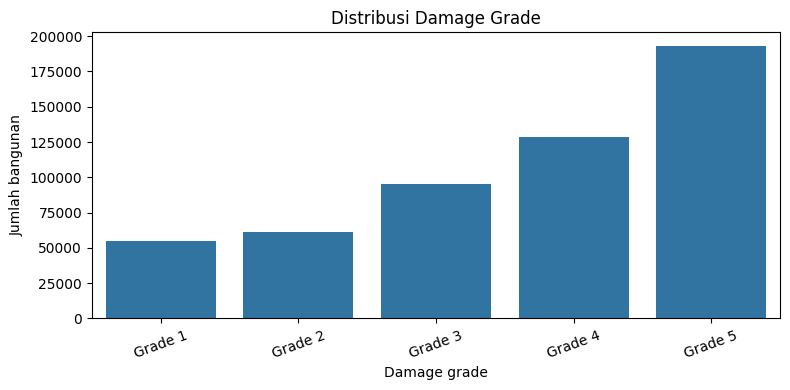

In [5]:
target_summary = pd.DataFrame({
    "count": train["damage_grade"].value_counts().sort_index(),
    "proportion": train["damage_grade"].value_counts(normalize=True).sort_index(),})
display(target_summary.round(4))

plt.figure(figsize=(8, 4))
sns.barplot(x=target_summary.index, y=target_summary["count"], color="C0")
plt.title("Distribusi Damage Grade")
plt.xlabel("Damage grade")
plt.ylabel("Jumlah bangunan")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Distribusi target tidak seimbang. Grade 5 merupakan kelas terbesar dan Grade 1 serta Grade 2 relatif lebih sedikit.

## 5. EDA fitur dan penetapan peran kolom

In [6]:
target = "damage_grade"
id_col = "building_id"
random_state = 42
label_order = ["Grade 1", "Grade 2", "Grade 3", "Grade 4", "Grade 5"]
grade_to_int = {label: idx for idx, label in enumerate(label_order)}
int_to_grade = np.array(label_order)

numeric_cols = ["count_floors_pre_eq","age_building","plinth_area_sq_ft","height_ft_pre_eq"]

categorical_cols = ["district_id","vdcmun_id","ward_id","land_surface_condition","foundation_type",
    "roof_type","ground_floor_type","other_floor_type","position","plan_configuration","superstructure",]

feature_cols = [col for col in train.columns if col not in [id_col, target]]

print("Jumlah fitur numerik:", len(numeric_cols))
print("Jumlah fitur kategorikal:", len(categorical_cols))
print("Jumlah fitur model tanpa ID:", len(feature_cols))
print("Label order:", label_order)

assert set(numeric_cols + categorical_cols) == set(feature_cols) # make sure kolom fitur suda lengkap
assert train[target].notna().all() # make sure target tidak ada missing value
assert set(train[target].unique()) == set(label_order) # make sure label target sesuai
assert train[id_col].is_unique and test[id_col].is_unique # maake sure id tidak duplikat
assert set(feature_cols) == (set(test.columns) - {id_col}) # make sure fitur dan kolom dataset sesuai
print("Pemeriksaan skema passed.")

print("\nRingkasan numerik:")
display(train[numeric_cols].describe().T)
print("\nRingkasan kategorikal:")
display(train[categorical_cols].describe().T)

Jumlah fitur numerik: 4
Jumlah fitur kategorikal: 11
Jumlah fitur model tanpa ID: 15
Label order: ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']
Pemeriksaan skema passed.

Ringkasan numerik:


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0



Ringkasan kategorikal:


,count,mean,std,min,25%,50%,75%,max
district_id,533465.0,25.764134,5.812230,12.0,22.0,24.0,30.0,36.0
vdcmun_id,533465.0,2582.312433,581.640567,1201.0,2204.0,2410.0,3010.0,3611.0
ward_id,533465.0,258236.686092,58164.132189,120101.0,220401.0,241004.0,301005.0,361108.0


## 6. EDA numerik: distribusi dan nilai khusus

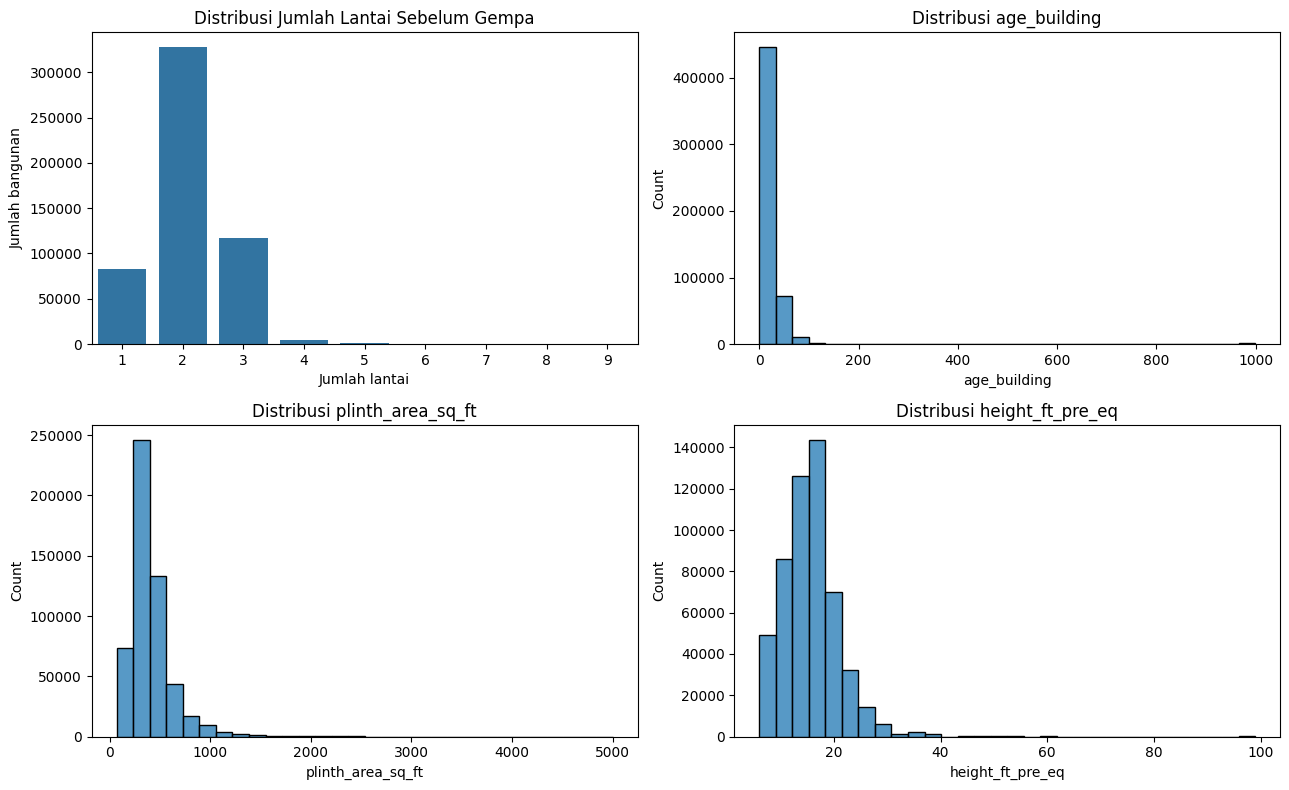

,feature,lower_bound_IQR,upper_bound_IQR,outlier_count,outlier_percent
0,age_building,-18.0,54.0,26735,5.012
1,plinth_area_sq_ft,-5.0,755.0,31219,5.852
2,height_ft_pre_eq,3.0,27.0,11724,2.198


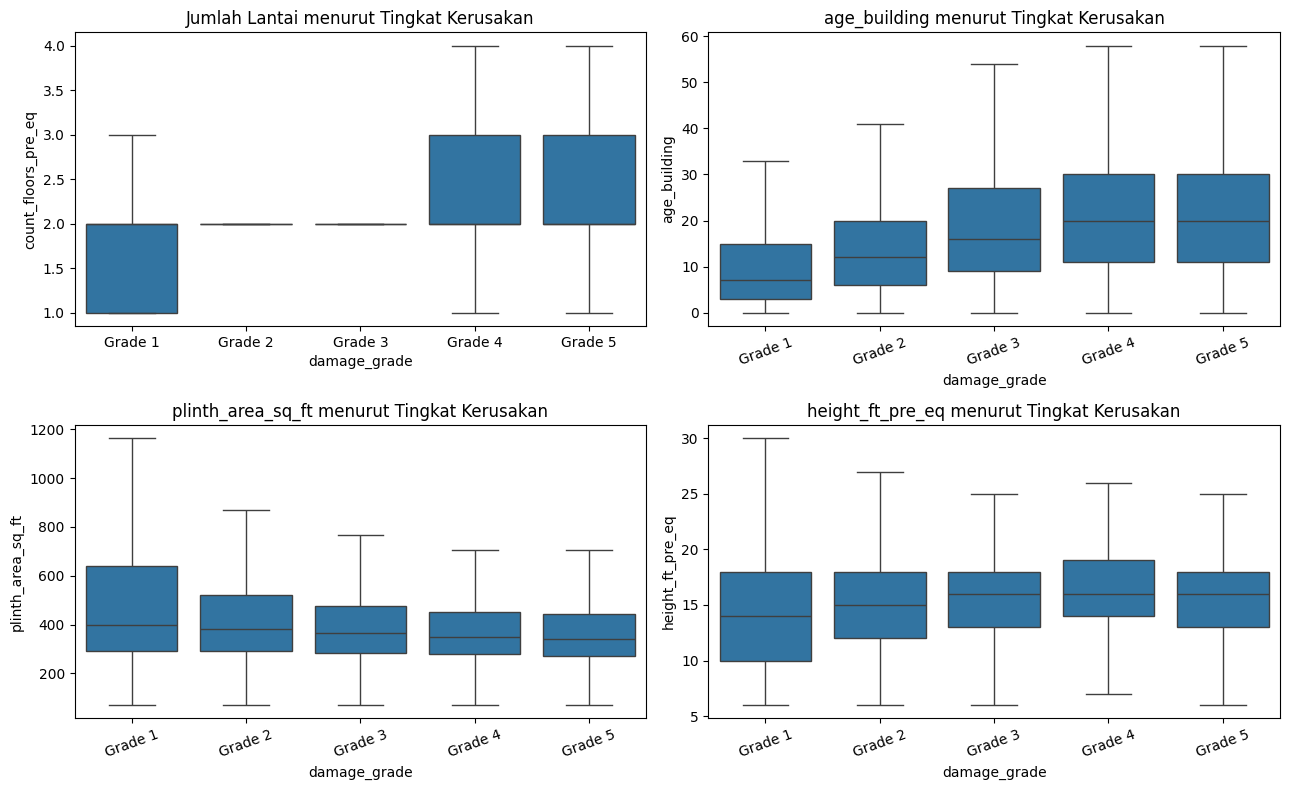

In [ ]:
# 1. Distribusi fitur numerik kontinu dan diskrit
# Bar Plot
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
floor_counts = train["count_floors_pre_eq"].value_counts().sort_index()
sns.barplot(x=floor_counts.index,y=floor_counts.values,ax=axes[0, 0],color="C0")

axes[0, 0].set_title("Distribusi Jumlah Lantai Sebelum Gempa")
axes[0, 0].set_xlabel("Jumlah lantai")
axes[0, 0].set_ylabel("Jumlah bangunan")

# Histogram
hist_cols = ["age_building","plinth_area_sq_ft","height_ft_pre_eq"]

for col, ax in zip(hist_cols, [axes[0, 1], axes[1, 0], axes[1, 1]]):
    sns.histplot(data=train, x=col, bins=30, ax=ax, color="C0")
    ax.set_title(f"Distribusi {col}")
plt.tight_layout()
plt.show()

# 2. Pemeriksaan outlier menggunakan IQR
iqr_cols = ["age_building","plinth_area_sq_ft","height_ft_pre_eq"]
outlier_rows = []

for col in iqr_cols:
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (train[col] < lower) | (train[col] > upper)

    outlier_rows.append({
        "feature": col,
        "lower_bound_IQR": lower,
        "upper_bound_IQR": upper,
        "outlier_count": int(mask.sum()),
        "outlier_percent": mask.mean() * 100})
display(pd.DataFrame(outlier_rows).round(3))

# 3. Perbandingan fitur numerik menurut tingkat kerusakan

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
# Jumlah lantai: bar plot
sns.boxplot(data=train,x=target,y="count_floors_pre_eq",
    order=label_order,showfliers=False,ax=axes[0, 0])
axes[0, 0].set_title("Jumlah Lantai menurut Tingkat Kerusakan")

for col, ax in zip(hist_cols, [axes[0, 1], axes[1, 0], axes[1, 1]]):
    sns.boxplot(data=train,x=target,y=col,
        order=label_order,showfliers=False,ax=ax)
    ax.set_title(f"{col} menurut Tingkat Kerusakan")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


Largest observed age values:


age_building
172       2
174       3
175       2
176       1
177       1
178       2
180      13
185       1
187       1
190       5
195       2
196       2
199       1
200     178
999    2198
Name: count, dtype: int64

Number of training rows with age_building = 999: 2198
Number of test rows with age_building = 999: 946


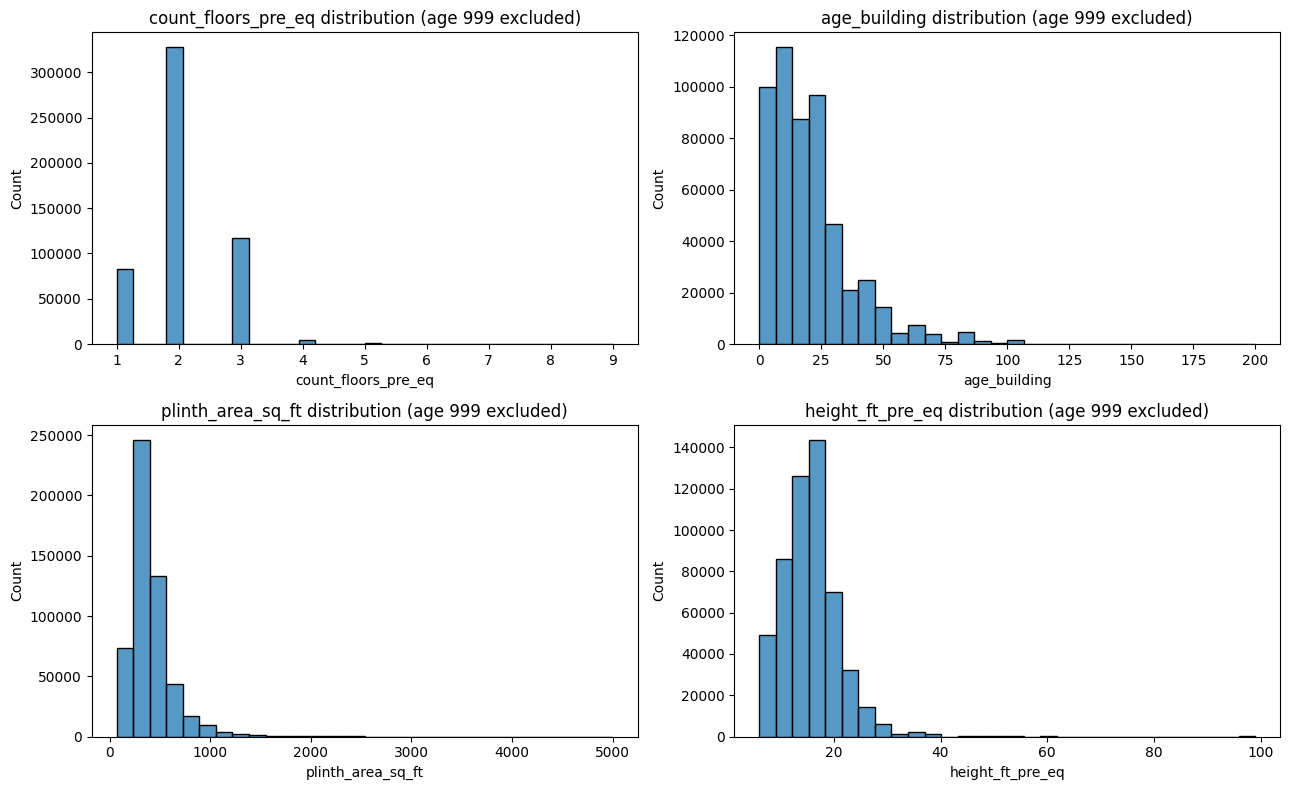

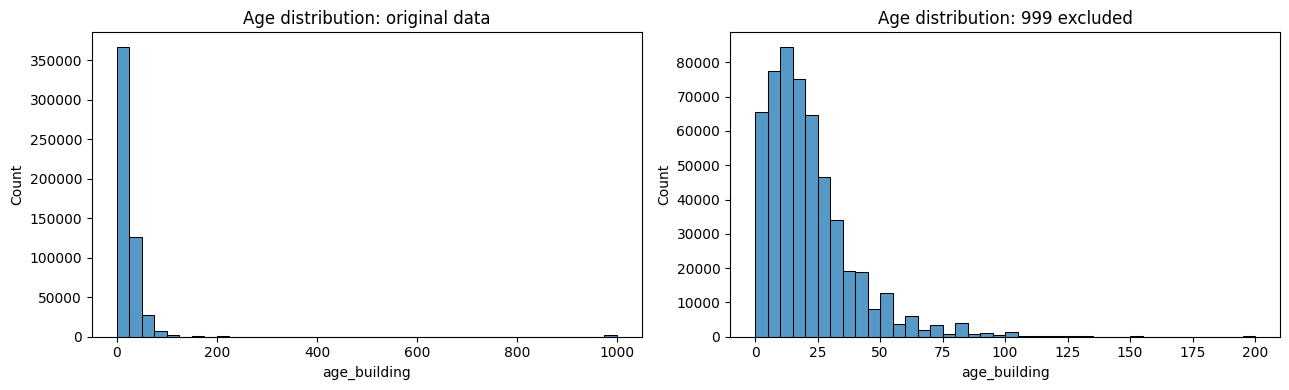

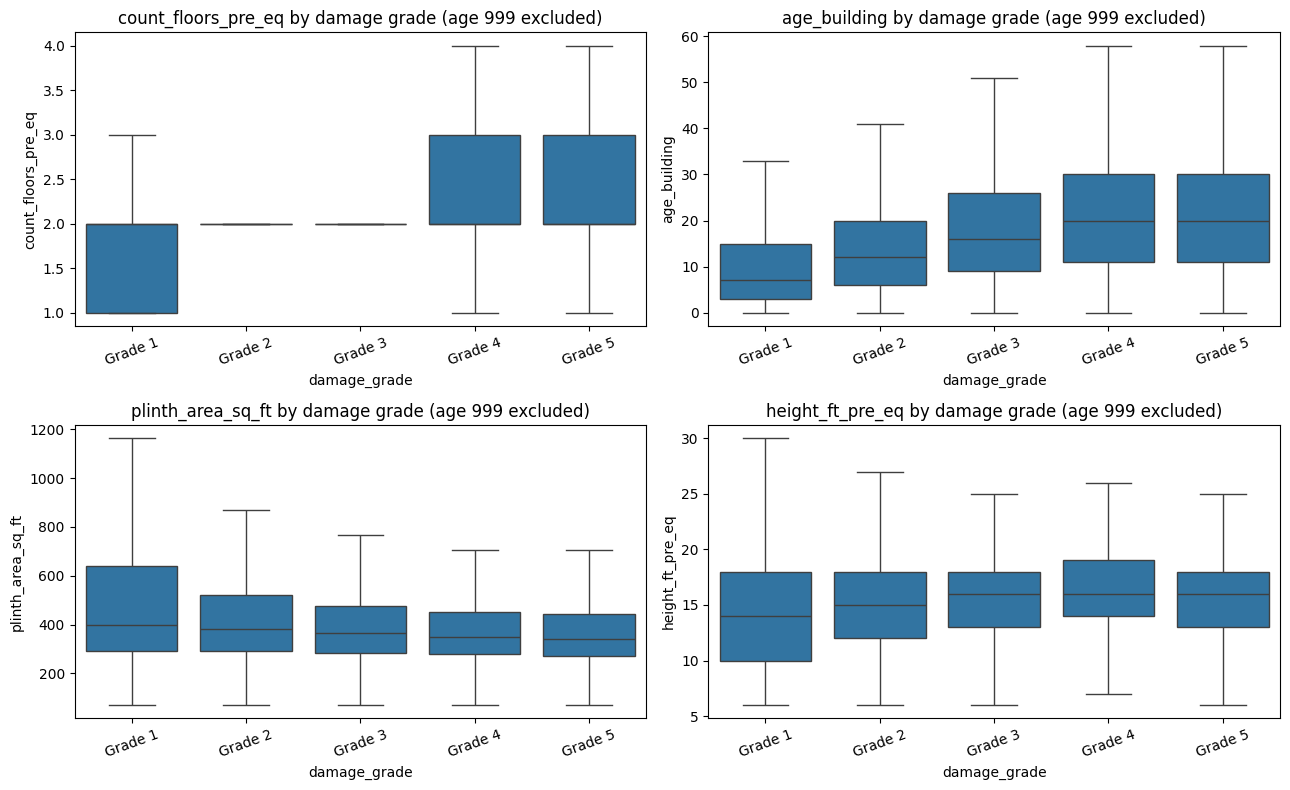

In [ ]:
# Cek nilai tak biasa di age building
print("Largest observed age values:")
display(train["age_building"]
    .value_counts()
    .sort_index()
    .tail(15))

print("Number of training rows with age_building = 999:",int((train["age_building"] == 999).sum()))

print("Number of test rows with age_building = 999:",int((test["age_building"] == 999).sum()))

# Melihat distribusi setelah menghilangkan 999
train_age_checked = train.copy()
train_age_checked.loc[
    train_age_checked["age_building"] == 999,"age_building"] = np.nan

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, ax in zip(numeric_cols, axes.ravel()):
    values = train_age_checked[col].dropna()
    sns.histplot(values, bins=30, ax=ax, color="C0")
    ax.set_title(f"{col} distribution (age 999 excluded)")

plt.tight_layout()
plt.show()


# Membandingkan age distribution before and after
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(train["age_building"],bins=40,ax=axes[0],color="C0")
axes[0].set_title("Age distribution: original data")

sns.histplot(train_age_checked["age_building"].dropna(),bins=40,ax=axes[1],color="C0")
axes[1].set_title("Age distribution: 999 excluded")

plt.tight_layout()
plt.show()

# Boxplots tanpa age = 999
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, ax in zip(numeric_cols, axes.ravel()):
    sns.boxplot(data=train_age_checked,x=target,y=col,
        order=label_order,showfliers=False,ax=ax)
    ax.set_title(f"{col} by damage grade (age 999 excluded)")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


Nilai 999 berada jauh di luar konsentrasi utama distribusi umur bangunan sehingga perlu diteliti lebih lanjut. Namun, metadata yang tersedia belum menjelaskan arti nilai 999. Oleh karena itu, kita belum dapat memastikan apakah nilai tersebut merupakan kode khusus, penanda data yang tidak diketahui, atau memiliki arti lain.

Perubahan pada tahap ini hanya digunakan untuk keperluan eksplorasi visualisasi. Data asli tetap dipertahankan.

Penanganan nilai tersebut baru akan dipertimbangkan melalui eksperimen modeling terkontrol, misalnya dengan mengubahnya menjadi nilai hilang dan menambahkan indikator khusus untuk menandai observasi yang memiliki nilai 999.

## 7. EDA kategorikal: proporsi kelas


district_id | jumlah kategori: 11


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
district_id,,,,,,
24,68616,0.085,0.120,0.257,0.294,0.244
31,63557,0.357,0.232,0.204,0.121,0.086
30,62461,0.056,0.084,0.171,0.292,0.397
23,62165,0.014,0.023,0.036,0.121,0.805
36,54751,0.057,0.110,0.198,0.289,0.347
28,53704,0.034,0.036,0.106,0.303,0.522
20,48133,0.192,0.209,0.251,0.230,0.119
22,42465,0.022,0.049,0.108,0.237,0.583
21,41095,0.037,0.122,0.288,0.358,0.195


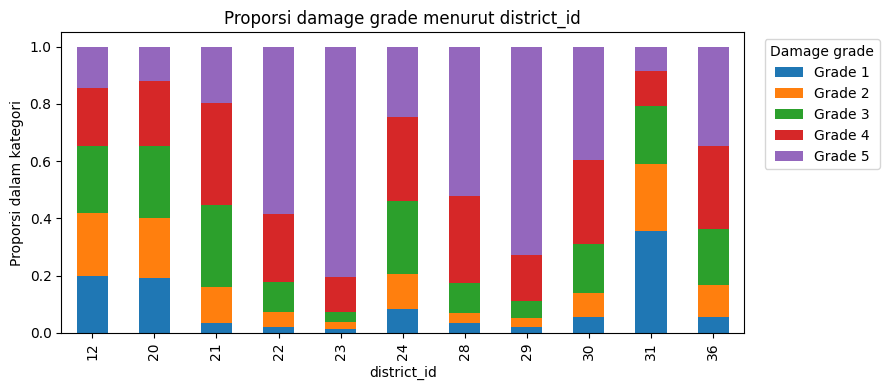


vdcmun_id | jumlah kategori: 110


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
vdcmun_id,,,,,,
3104,22770,0.496,0.254,0.139,0.057,0.054
2005,10946,0.186,0.220,0.242,0.229,0.122
3009,10718,0.108,0.062,0.133,0.391,0.306
2802,10590,0.100,0.061,0.099,0.278,0.463
2001,10510,0.356,0.254,0.255,0.097,0.039
2304,10176,0.025,0.029,0.026,0.127,0.792
2310,9705,0.011,0.020,0.045,0.177,0.747
2105,9456,0.043,0.106,0.269,0.409,0.172
3608,9296,0.150,0.158,0.222,0.293,0.177



ward_id | jumlah kategori: 945


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
ward_id,,,,,,
310405,1803,0.702,0.155,0.094,0.023,0.027
310404,1692,0.601,0.247,0.121,0.021,0.010
310412,1599,0.402,0.287,0.100,0.082,0.129
200506,1442,0.307,0.252,0.228,0.157,0.057
310419,1380,0.436,0.262,0.127,0.114,0.061
310411,1378,0.528,0.239,0.134,0.052,0.047
241004,1331,0.252,0.157,0.159,0.361,0.072
310415,1330,0.802,0.082,0.047,0.008,0.062
310409,1321,0.396,0.309,0.159,0.063,0.073



land_surface_condition | jumlah kategori: 3


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
land_surface_condition,,,,,,
Flat,442089,0.109,0.116,0.176,0.235,0.364
Moderate slope,73944,0.076,0.112,0.194,0.273,0.345
Steep slope,17432,0.077,0.092,0.184,0.261,0.386


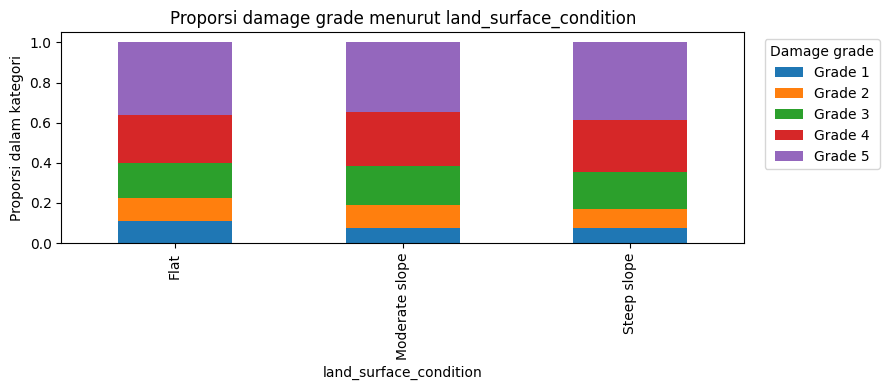


foundation_type | jumlah kategori: 5


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
foundation_type,,,,,,
Mud mortar-Stone/Brick,440105,0.047,0.089,0.179,0.268,0.417
Bamboo/Timber,40167,0.301,0.233,0.232,0.144,0.091
Cement-Stone/Brick,27562,0.296,0.226,0.180,0.143,0.155
RC,22445,0.595,0.268,0.098,0.022,0.016
Other,3186,0.297,0.089,0.097,0.153,0.365


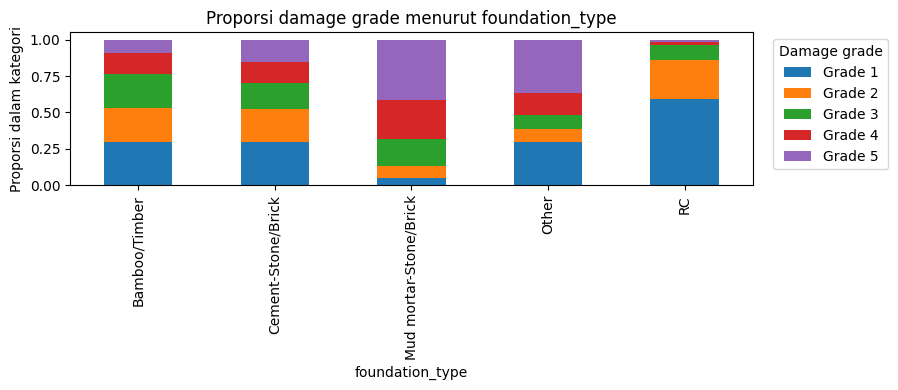


roof_type | jumlah kategori: 3


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
roof_type,,,,,,
Bamboo/Timber-Light roof,352493,0.082,0.105,0.178,0.259,0.376
Bamboo/Timber-Heavy roof,149836,0.063,0.104,0.193,0.242,0.398
RCC/RB/RBC,31136,0.546,0.276,0.120,0.035,0.023


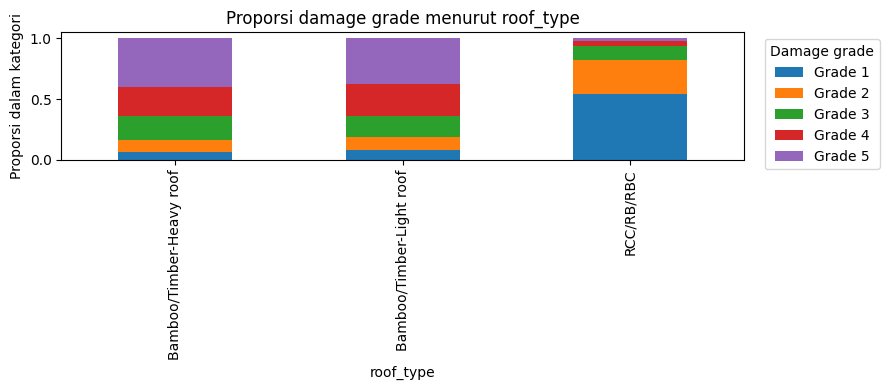


ground_floor_type | jumlah kategori: 5


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
ground_floor_type,,,,,,
Mud,432806,0.062,0.096,0.184,0.261,0.397
RC,51146,0.462,0.276,0.149,0.067,0.047
Brick/Stone,46264,0.089,0.102,0.164,0.252,0.393
Timber,2507,0.195,0.189,0.148,0.205,0.264
Other,742,0.279,0.190,0.232,0.158,0.142


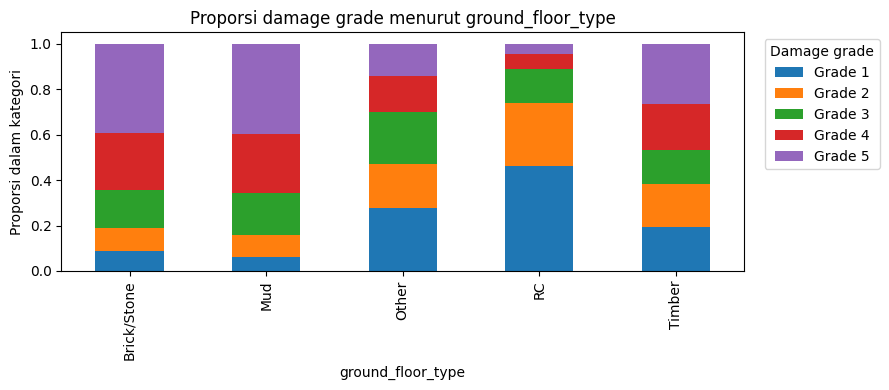


other_floor_type | jumlah kategori: 4


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
other_floor_type,,,,,,
TImber/Bamboo-Mud,340906,0.041,0.090,0.191,0.287,0.391
Timber-Planck,86637,0.093,0.109,0.171,0.217,0.410
Not applicable,83103,0.259,0.177,0.152,0.131,0.281
RCC/RB/RBC,22819,0.512,0.273,0.131,0.048,0.036


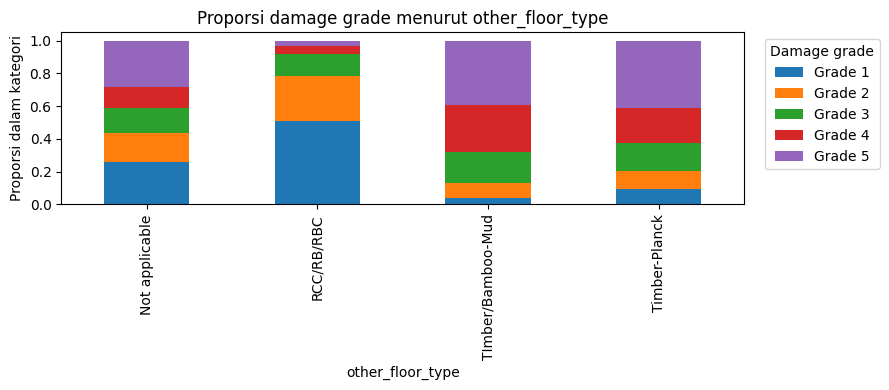


position | jumlah kategori: 4


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
position,,,,,,
Not attached,423151,0.103,0.116,0.183,0.241,0.356
Attached-1 side,90493,0.084,0.097,0.162,0.247,0.409
Attached-2 side,18943,0.189,0.152,0.171,0.209,0.279
Attached-3 side,878,0.269,0.181,0.173,0.219,0.158


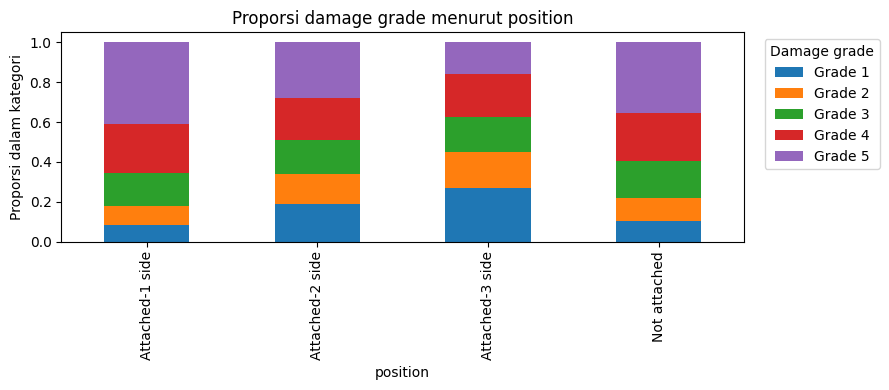


plan_configuration | jumlah kategori: 10


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
plan_configuration,,,,,,
Rectangular,511999,0.099,0.113,0.179,0.244,0.365
Square,12229,0.147,0.105,0.134,0.187,0.427
L-shape,7009,0.277,0.215,0.208,0.178,0.121
T-shape,668,0.192,0.202,0.232,0.184,0.190
Multi-projected,636,0.297,0.220,0.263,0.162,0.058
Others,387,0.416,0.116,0.243,0.127,0.098
U-shape,313,0.259,0.243,0.198,0.160,0.141
E-shape,99,0.152,0.152,0.202,0.222,0.273
Building with Central Courtyard,64,0.344,0.312,0.141,0.125,0.078


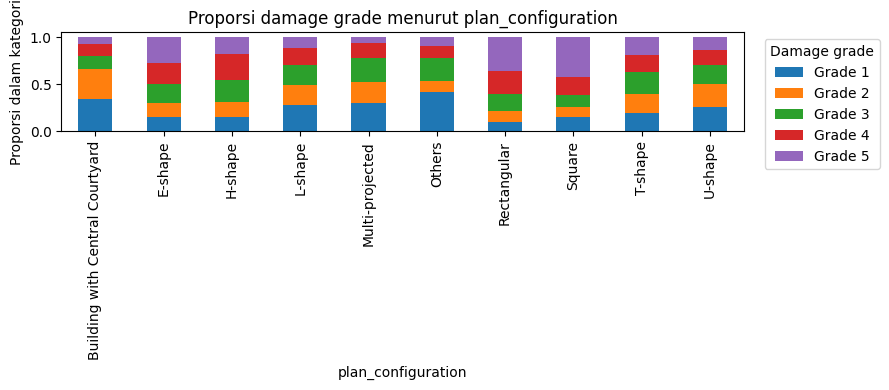


superstructure | jumlah kategori: 11


,count,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5
superstructure,,,,,,
has_superstructure_mud_mortar_stone,415327,0.038,0.086,0.178,0.271,0.428
has_superstructure_cement_mortar_brick,33289,0.464,0.311,0.156,0.043,0.026
has_superstructure_timber,25407,0.390,0.217,0.198,0.110,0.085
has_superstructure_adobe_mud,22574,0.046,0.110,0.251,0.305,0.289
has_superstructure_rc_non_engineered,9051,0.586,0.276,0.102,0.018,0.018
has_superstructure_stone_flag,6994,0.021,0.080,0.153,0.244,0.502
has_superstructure_mud_mortar_brick,6746,0.098,0.180,0.291,0.314,0.117
has_superstructure_rc_engineered,5475,0.719,0.214,0.053,0.007,0.007
has_superstructure_cement_mortar_stone,4946,0.298,0.226,0.190,0.141,0.144


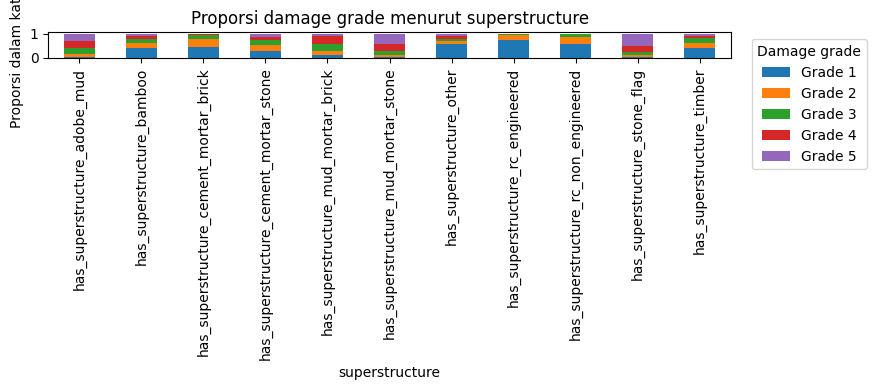

In [9]:
for col in categorical_cols:
    counts = train[col].value_counts(dropna=False).rename("count")
    proportions = pd.crosstab(
        train[col], train[target], normalize="index").reindex(columns=label_order, fill_value=0)
    summary = counts.to_frame().join(proportions)
    print(f"\n{col} | jumlah kategori: {train[col].nunique(dropna=False)}")
    display(summary.sort_values("count", ascending=False).head(10).round(3))

    if train[col].nunique(dropna=False) <= 15:
        proportions.plot(kind="bar", stacked=True, figsize=(9, 4))
        plt.title(f"Proporsi damage grade menurut {col}")
        plt.xlabel(col)
        plt.ylabel("Proporsi dalam kategori")
        plt.legend(title="Damage grade", bbox_to_anchor=(1.02, 1))
        plt.tight_layout()
        plt.show()

### Interpretasi kategorikal

Distribusi damage grade berbeda menurut beberapa kategori lokasi dan struktur. Sebagai contoh, beberapa distrik memiliki proporsi Grade 5 yang jauh lebih tinggi dibanding distrik lain, sedangkan jenis fondasi dan atap juga menunjukkan perbedaan proporsi kelas. Penggunaan model diperkirakan yang bisa memanfaatkan fitur kategorikal dan interaksi nonlinier.